# Does the shape of the curve matter, or only its endpoint?

Notebook 01 used a single snapshot: score and comment counts at time `t`. The collector actually
fetched every story roughly every 10 minutes, so at `t` we also know *how* the story got there.
This notebook adds trajectory features and asks whether they help, using a paired bootstrap on
the same held-out days so the comparison is like-for-like.

Trajectory features (all computed from snapshots at age <= t):

| feature | meaning |
| --- | --- |
| `velocity_10m`, `velocity_30m` | points gained over the last 10 / 30 minutes |
| `log_score_half` | score at t/2 (with the score at t, an acceleration proxy) |
| `min_to_first_point`, `min_to_first_comment` | minutes until the first upvote / comment, censored at t |
| `comments_per_point` | discussion intensity |
| `n_snapshots`, `obs_age_min` | data-coverage controls: how many fetches, and how stale the last one is |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

from hn import dataset, evaluate, models

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
xgb_params = json.load(open("xgb_params.json"))

In [2]:
def fit_predict(model, train, test, cols):
    pipe = models.make_pipeline(model, cols)
    pipe.fit(train[cols], train.top30)
    return pipe, pipe.predict_proba(test[cols])[:, 1]

results = []
for t in [30, 60, 120]:
    df = dataset.build(t, trajectory=True)
    train, test = dataset.temporal_split(df)
    all_cols = dataset.feature_columns(df)
    point_cols = [c for c in all_cols if c in dataset.feature_columns(dataset.build(t))]
    for model_name, make in [("logistic", lambda: models.logistic()),
                             ("xgboost", lambda: models.xgb_classifier(models.pos_weight(train.top30), **xgb_params))]:
        _, p_point = fit_predict(make(), train, test, point_cols)
        pipe, p_traj = fit_predict(make(), train, test, all_cols)
        ap_point = evaluate.bootstrap_ci(test.top30, p_point)
        ap_traj = evaluate.bootstrap_ci(test.top30, p_traj)
        diff = evaluate.paired_bootstrap_diff(test.top30, p_point, p_traj)
        results.append({"t_min": t, "model": model_name,
                        "AUPRC point": round(ap_point[0], 3), "AUPRC +trajectory": round(ap_traj[0], 3),
                        "diff": round(diff[0], 3), "diff 95% CI": f"[{diff[1]:.3f}, {diff[2]:.3f}]"})
pd.DataFrame(results)

,t_min,model,AUPRC point,AUPRC +trajectory,diff,diff 95% CI
0,30,logistic,0.364,0.392,0.028,"[0.000, 0.056]"
1,30,xgboost,0.295,0.326,0.031,"[-0.031, 0.095]"
2,60,logistic,0.567,0.635,0.068,"[0.018, 0.121]"
3,60,xgboost,0.513,0.584,0.071,"[0.012, 0.135]"
4,120,logistic,0.731,0.731,-0.001,"[-0.059, 0.058]"
5,120,xgboost,0.639,0.729,0.090,"[0.021, 0.174]"


A difference whose 95% interval excludes zero is a real improvement on these two test days;
an interval straddling zero means the trajectory added nothing we can distinguish from noise.

## Which kinds of information does the model use?

Permutation importance by feature *group*, on the held-out days, for the logistic model with
trajectory features: shuffle every column in a group across test rows and measure how much AUPRC
drops. Groups rather than single columns because the title is 2,000 correlated n-gram columns and
the trajectory features are correlated with the score they are derived from.

In [3]:
GROUPS = {
    "score at t": ["log_score"],
    "comments at t": ["log_descendants", "log_kids_count"],
    "trajectory": ["velocity_10m", "velocity_30m", "log_score_half", "min_to_first_point",
                   "min_to_first_comment", "comments_per_point", "n_snapshots", "obs_age_min"],
    "title": ["title"],
    "domain": ["domain"],
    "timing": ["hour_utc", "dow_utc"],
    "flags": ["is_show_hn", "is_ask_hn", "url_missing"],
}

def group_permutation_drop(pipe, test, cols, n_repeats=10, seed=0):
    rng = np.random.default_rng(seed)
    base = average_precision_score(test.top30, pipe.predict_proba(test[cols])[:, 1])
    drops = {}
    for name, group in GROUPS.items():
        vals = []
        for _ in range(n_repeats):
            shuffled = test[cols].copy()
            shuffled[group] = shuffled[group].sample(frac=1, random_state=rng.integers(1e9)).values
            vals.append(base - average_precision_score(test.top30, pipe.predict_proba(shuffled)[:, 1]))
        drops[name] = np.mean(vals)
    return pd.Series(drops, name="AUPRC drop when shuffled")

drops = {}
for t in [30, 60, 120]:
    df = dataset.build(t, trajectory=True)
    train, test = dataset.temporal_split(df)
    cols = dataset.feature_columns(df)
    pipe, _ = fit_predict(models.logistic(), train, test, cols)
    drops[f"t = {t}"] = group_permutation_drop(pipe, test, cols)
drops = pd.DataFrame(drops)
drops.round(3)

,t = 30,t = 60,t = 120
score at t,0.104,0.521,0.323
comments at t,0.004,0.004,0.017
trajectory,0.203,0.103,0.316
title,-0.002,0.001,0.000
domain,-0.006,0.002,0.003
timing,0.002,0.001,0.000
flags,0.012,0.004,0.005


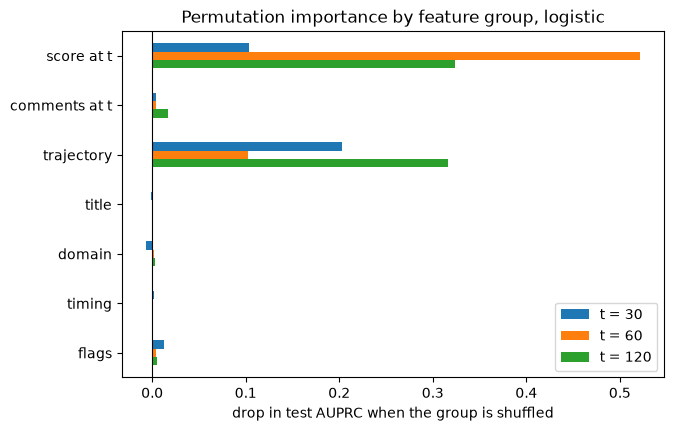

In [4]:
ax = drops.plot.barh(figsize=(7, 4.5))
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="drop in test AUPRC when the group is shuffled", title="Permutation importance by feature group, logistic")
ax.invert_yaxis(); ax.figure.savefig(FIG / "feature_importance.png", dpi=120, bbox_inches="tight")

## Takeaway

- Trajectory features help where it matters: at 30 minutes the gain is small and its interval
  only touches zero for the linear model; at 60 minutes both models gain about 0.07 AUPRC with
  intervals clearly above zero. By two hours the current score already summarizes the history and
  the linear model gains nothing (XGBoost still does, but its point-feature version was weaker to
  begin with).
- The permutation chart splits the signal into two kinds. **Engagement counts and their history**
  (score, trajectory) account for essentially all of the model's skill; the two groups are
  collinear (at t = 30, `velocity_30m` is the score minus one), so shuffling one is partly
  compensated by the other and their individual drops should be read together. **Everything the
  model knows about the story itself** (title n-grams, domain, posting time, Show/Ask flags) moves
  test AUPRC by a hundredth or less. Early prediction on HN is about watching the votes come in,
  not about reading the title.